# Classification: training, tuning and held-out evaluation

New reconstruction with training-only preprocessing. Stratified 72/18 split, seed 42, five-fold CV. Includes logistic regression, SVM, tree and KNN. ReusedCount needs a prelaunch-availability audit. The upstream course payload column was already imputed.

Executed reconstruction created for this report. These are not recovered copies of previously unshared learner notebooks.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, json
from IPython.display import display, Image, HTML
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)


In [2]:
import runpy
# Execute the actual training pipeline rather than merely loading saved scores.
runpy.run_path(str(ROOT/'src/train_and_analyze.py'))
r=json.loads((RESULTS/'analysis_results.json').read_text());scores=pd.DataFrame(r['ml']);display(scores[['name','cv','cvstd','test','precision','recall','f1','params']])

{
  "sql": [
    {
      "query": "SELECT DISTINCT Launch_Site FROM launches ORDER BY Launch_Site",
      "rows": [
        {
          "Launch_Site": "CCAFS LC-40"
        },
        {
          "Launch_Site": "CCAFS SLC-40"
        },
        {
          "Launch_Site": "KSC LC-39A"
        },
        {
          "Launch_Site": "VAFB SLC-4E"
        }
      ]
    },
    {
      "query": "SELECT Date,Booster_Version,Launch_Site FROM launches WHERE Launch_Site LIKE 'CCA%' ORDER BY Date LIMIT 5",
      "rows": [
        {
          "Date": "2010-06-04",
          "Booster_Version": "F9 v1.0  B0003",
          "Launch_Site": "CCAFS LC-40"
        },
        {
          "Date": "2010-12-08",
          "Booster_Version": "F9 v1.0  B0004",
          "Launch_Site": "CCAFS LC-40"
        },
        {
          "Date": "2012-05-22",
          "Booster_Version": "F9 v1.0  B0005",
          "Launch_Site": "CCAFS LC-40"
        },
        {
          "Date": "2012-10-08",
          "Booster_Versio

,name,cv,cvstd,test,precision,recall,f1,params
0,Logistic regression,0.848571,0.063489,0.777778,0.750000,1.000000,0.857143,{'model__C': 0.1}
1,SVM,0.888571,0.069046,0.777778,0.750000,1.000000,0.857143,"{'model__C': 1, 'model__gamma': 'scale', 'mode..."
2,Decision tree,0.845714,0.071625,0.833333,0.800000,1.000000,0.888889,"{'model__criterion': 'gini', 'model__max_depth..."
3,KNN,0.889524,0.090220,0.777778,0.785714,0.916667,0.846154,"{'model__n_neighbors': 3, 'model__p': 1, 'mode..."


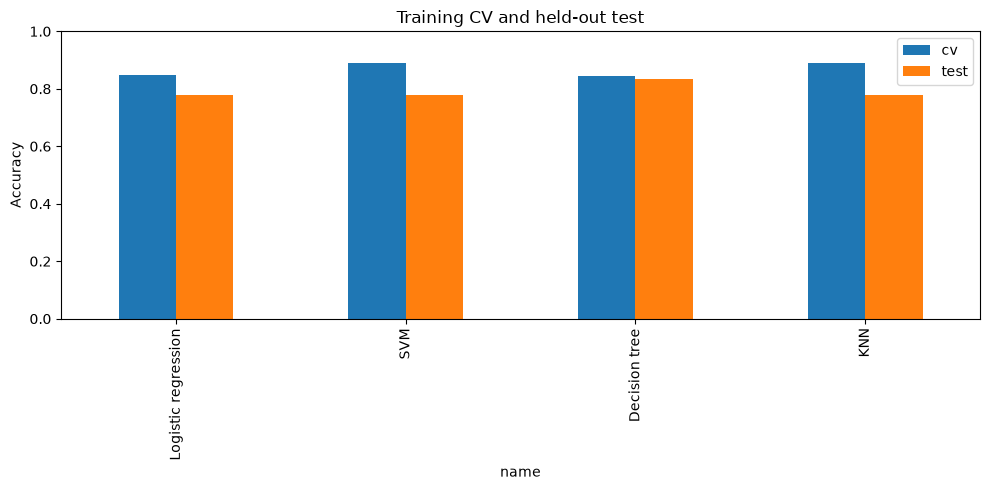

,Predicted 0,Predicted 1
Actual 0,3,3
Actual 1,0,12


,Predicted 0,Predicted 1
Actual 0,3,3
Actual 1,1,11


Tree: highest observed test accuracy. KNN: selected by mean CV. Test set contains 18 launches, baseline 12/18.


In [3]:
import matplotlib.pyplot as plt
scores.set_index('name')[['cv','test']].plot.bar(ylim=(0,1),figsize=(10,5),ylabel='Accuracy',title='Training CV and held-out test');plt.tight_layout();plt.show()
for name in ['Decision tree','KNN']:
    item=next(m for m in r['ml'] if m['name']==name);display(pd.DataFrame(item['cm'],index=['Actual 0','Actual 1'],columns=['Predicted 0','Predicted 1']))
print('Tree: highest observed test accuracy. KNN: selected by mean CV. Test set contains 18 launches, baseline 12/18.')